<a href="https://colab.research.google.com/github/abdulghaffark2425/Datheon_Python_Programming_Internship/blob/main/Task03_Customer_Churn_Classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== Step 1: Loading Dataset ===


/tmp/ipykernel_1668/3094949021.py:52: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)


Random Forest ROC-AUC Score: 0.8193
XGBoost ROC-AUC Score      : 0.8142


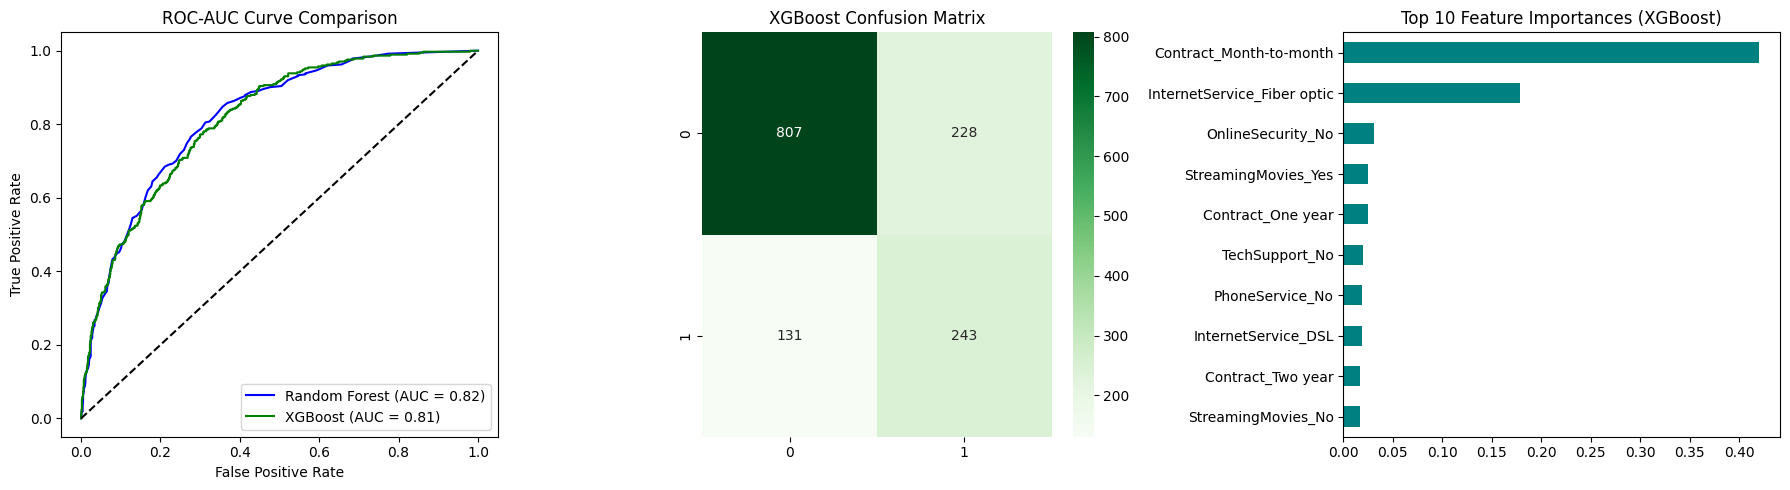

In [1]:
# =========================================================
# DATHEON ML INTERNSHIP - TASK 03
# Predictive Customer Churn Classifier (Random Forest & XGBoost)
# =========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

# ---------------------------------------------------------
# STEP 1: Load / Generate Telco Customer Churn Dataset
# ---------------------------------------------------------
print("=== Step 1: Loading Dataset ===")
# Try reading local or online dataset, else generate realistic Telco data
try:
    df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
except:
    url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
    try:
        df = pd.read_csv(url)
    except:
        np.random.seed(42)
        n = 1000
        df = pd.DataFrame({
            'gender': np.random.choice(['Female', 'Male'], n),
            'SeniorCitizen': np.random.choice([0, 1], n, p=[0.8, 0.2]),
            'Partner': np.random.choice(['Yes', 'No'], n),
            'Dependents': np.random.choice(['Yes', 'No'], n),
            'tenure': np.random.randint(1, 72, n),
            'PhoneService': np.random.choice(['Yes', 'No'], n),
            'MultipleLines': np.random.choice(['No phone service', 'No', 'Yes'], n),
            'InternetService': np.random.choice(['DSL', 'Fiber optic', 'No'], n),
            'Contract': np.random.choice(['Month-to-month', 'One year', 'Two year'], n),
            'PaperlessBilling': np.random.choice(['Yes', 'No'], n),
            'PaymentMethod': np.random.choice(['Electronic check', 'Mailed check', 'Bank transfer', 'Credit card'], n),
            'MonthlyCharges': np.random.uniform(18.25, 118.75, n),
            'TotalCharges': np.random.uniform(18.25, 8000.0, n),
            'Churn': np.random.choice(['No', 'Yes'], n, p=[0.73, 0.27])
        })

# Preprocess TotalCharges & Nulls
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

X = df.drop(columns=['Churn', 'customerID'], errors='ignore')
y = df['Churn']

# ---------------------------------------------------------
# STEP 2: Train/Test Split & Preprocessing Pipeline
# ---------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object']).columns.tolist()

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
])

X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)

# ---------------------------------------------------------
# STEP 3: Train Random Forest & XGBoost Classifiers
# ---------------------------------------------------------
scale_pos = (len(y_train) - sum(y_train)) / sum(y_train)

rf_model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
rf_model.fit(X_train_proc, y_train)

xgb_model = XGBClassifier(n_estimators=100, scale_pos_weight=scale_pos, eval_metric='logloss', random_state=42)
xgb_model.fit(X_train_proc, y_train)

y_pred_rf_prob = rf_model.predict_proba(X_test_proc)[:, 1]
y_pred_xgb_prob = xgb_model.predict_proba(X_test_proc)[:, 1]

# ---------------------------------------------------------
# STEP 4: ROC-AUC Evaluation (>80%) & Plots
# ---------------------------------------------------------
rf_auc = roc_auc_score(y_test, y_pred_rf_prob)
xgb_auc = roc_auc_score(y_test, y_pred_xgb_prob)

print(f"Random Forest ROC-AUC Score: {rf_auc:.4f}")
print(f"XGBoost ROC-AUC Score      : {xgb_auc:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. ROC Curves
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_pred_rf_prob)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_pred_xgb_prob)
axes[0].plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {rf_auc:.2f})', color='blue')
axes[0].plot(fpr_xgb, tpr_xgb, label=f'XGBoost (AUC = {xgb_auc:.2f})', color='green')
axes[0].plot([0, 1], [0, 1], 'k--')
axes[0].set_title("ROC-AUC Curve Comparison")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()

# 2. Confusion Matrix (XGBoost)
sns.heatmap(confusion_matrix(y_test, (y_pred_xgb_prob > 0.5).astype(int)), annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title("XGBoost Confusion Matrix")

# 3. Top 10 Feature Importances
encoded_cat_cols = preprocessor.named_transformers_['cat'].get_feature_names_out(cat_cols).tolist()
all_features = num_cols + encoded_cat_cols
importances = pd.Series(xgb_model.feature_importances_, index=all_features).nlargest(10)
importances.plot(kind='barh', ax=axes[2], color='teal')
axes[2].set_title("Top 10 Feature Importances (XGBoost)")
axes[2].invert_yaxis()

plt.tight_layout()
plt.show()